# A2 · The Bloch Equation

**Part:** A – Physics of the MRI signal · **Reading time:** ~75 min · **Pass 1 overview:** [What MRI measures](../pass1_big_picture/P1.1_What_MRI_Measures.ipynb) · **Refreshers you may want:** [ODEs for MRI](../refreshers/RM1_ODEs_for_MRI.ipynb), [Complex numbers and rotations](../refreshers/RM2_Complex_Numbers_and_Rotations.ipynb), [Precession and torque](../refreshers/RP3_Precession_and_Torque.ipynb)

The **Bloch equation**, named after the physicist Felix Bloch (Nobel Prize 1952 for the discovery of nuclear magnetic resonance in condensed matter), describes almost all behaviour of the net magnetization seen in MRI. It is a single vector differential equation. In this chapter we take it apart term by term, solve each important special case by hand (free precession, relaxation, excitation on and off resonance), derive the **rotating frame** properly, and build a numerical Bloch simulator. Everything later in the book—contrast, echoes, RF pulses, imaging—is a consequence of this equation.

## Learning goals

1. Understand what MRI is measuring
    * Mathematically define the net magnetization and write down the Bloch equation, explaining every term
1. Describe the concepts of polarization, resonance, excitation, and relaxation
    * Describe the rotation of the net magnetization due to interaction with magnetic fields (precession, left-handed)
    * Understand how to use the rotating frame to simplify descriptions of magnetic resonance, and derive the effective field $\vec B_{eff}$
    * Compute flip angles of RF pulses and predict the result of on- and off-resonant excitation
    * Describe the process of relaxation and derive the $T_1$ and $T_2$ solutions
1. Simulate the Bloch equation numerically (rotation-then-relaxation stepping) and judge its accuracy

## Symbols used in this chapter

| Symbol | Meaning (plain words) | SI unit | Typical value / remark |
|---|---|---|---|
| $\vec r$ | position | m | |
| $t$, $\tau$ | time; dummy integration variable | s | |
| $\vec M(\vec r,t)=[M_x,M_y,M_z]^T$ | net magnetization (lab frame) | A/m (normalized: $M_0=1$) | |
| $M_{xy}=M_x+iM_y$ | transverse magnetization as a complex number | same | some texts write $z$; we avoid $z$ (= position) |
| $M_z$ | longitudinal magnetization | same | |
| $M_0(\vec r)$ | equilibrium magnetization | same | |
| $\vec M'$, $M'_{xy}$ | magnetization seen in the rotating frame | same | |
| $\vec B(\vec r,t)=[B_x,B_y,B_z]^T$ | magnetic field (lab frame) | T | |
| $B_0$ | main static field along $z$ | T | 1.5, 3 T; toy values in demos |
| $\Delta B_0(\vec r)$ | deviation of the static field from $B_0$ | T | ppm of $B_0$ |
| $B_1$ | amplitude of the RF field | T | 1–25 µT |
| $b_1(t)=B_{1,x}+iB_{1,y}$ | complex envelope of the RF field in the rotating frame | T | |
| $B_1^+$ | co-rotating (effective) circularly polarized part of the RF field | T | |
| $\vec B_{eff}$ | effective field in the rotating frame | T | |
| $\gamma$, $\bar\gamma=\gamma/2\pi$ | gyromagnetic ratio | rad s⁻¹ T⁻¹; Hz/T | $2.675\times10^8$; 42.58 MHz/T |
| $\omega_0=\gamma B_0$, $f_0=\bar\gamma B_0$ | Larmor (angular) frequency | rad/s; Hz | 127.7 MHz @3 T |
| $\omega_{rf}$, $f_{rf}$ | frequency of the RF field = rotation rate of the rotating frame | rad/s; Hz | ≈ $\omega_0$ |
| $\Delta\omega=\omega_0-\omega_{rf}$, $\Delta f=\Delta\omega/2\pi$ | off-resonance (in the rotating frame) | rad/s; Hz | Hz–kHz |
| $\omega_{eff}$ | rotation rate about $\vec B_{eff}$ | rad/s | |
| $\alpha$ | tilt of $\vec B_{eff}$ away from the $z$-axis | rad | |
| $T_1$, $T_2$ | longitudinal / transverse relaxation **time constants** | s | $T_1$ 0.25–4 s, $T_2$ 10 ms–2 s |
| $R_1=1/T_1$, $R_2=1/T_2$ | relaxation **rates** | s⁻¹ | |
| $\theta$ | flip angle | rad (or °) | 90° = $\pi/2$ |
| $\phi_{rf}$ | phase of the RF field (direction of $b_1$ in the $x'y'$ plane) | rad | |
| $T_{rf}$ | RF pulse duration | s | 0.1–10 ms |
| $\Delta t$ | numerical time step | s | |
| $i$ | imaginary unit $\sqrt{-1}$ | – | |
| $\hat x,\hat y,\hat z$ | unit vectors along the axes | – | |

> **⚠️ Common confusion:** the original notation table calls $T_1$ and $T_2$ "relaxation rates". They are **time constants** (seconds). The rates are $R_1=1/T_1$ and $R_2=1/T_2$ (per second).

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))   # make ../mri_tools.py importable
import numpy as np
import matplotlib.pyplot as plt
import mri_tools as mt
mt.setup_plots()
%matplotlib inline

## 1 THE Bloch equation

The Bloch equation describes how the net magnetization $\vec M(\vec r,t)$ changes in a magnetic field $\vec B(\vec r,t)$ and can describe the vast majority of all MRI phenomena. While the complete equation is presented here, we typically use results *derived* from it to analyse and design MRI experiments.

$$
\frac{d\vec{M}(\vec{r},t)}{dt} =
\underbrace{\gamma\, \vec{M}(\vec{r},t) \times \vec{B}(\vec{r},t)}_{\text{precession}}
+
\underbrace{\begin{bmatrix}
-1/T_2(\vec{r})& 0 & 0 \\
0 & -1/T_2(\vec{r}) & 0 \\
0 & 0 & -1/T_1(\vec{r})
\end{bmatrix}
\vec{M}(\vec{r},t)
+
\begin{bmatrix}
 0 \\
 0 \\
M_0(\vec{r})/T_1(\vec{r})
\end{bmatrix}}_{\text{relaxation}}
$$

In words: the rate of change of the magnetization is the sum of a rotation around the magnetic field (precession) and a pull back towards equilibrium (relaxation), with transverse components decaying with $T_2$ and the longitudinal component recovering to $M_0$ with $T_1$.

where
* $\vec M(\vec r,t)$ [A/m, normalized] is the net magnetization at position $\vec r$ and time $t$, and $d\vec M/dt$ its rate of change [A m⁻¹ s⁻¹],
* $\gamma$ [rad s⁻¹ T⁻¹] is the gyromagnetic ratio ($2.675\times10^8$ for ¹H),
* $\vec B(\vec r,t)$ [T] is the total magnetic field: main field + gradients + RF,
* $M_0(\vec r)$ is the equilibrium magnetization, $T_1(\vec r)$ the longitudinal ($M_z$) or spin–lattice relaxation time constant, $T_2(\vec r)$ the transverse ($M_{xy}$) or spin–spin relaxation time constant [s].

The behaviour depends on the tissue constants $M_0$, $T_1$, $T_2$, all of which vary across the subject (and all are a valuable source of contrast!). Everything else—$\vec B(\vec r,t)$—is under our control through the scanner hardware.

A full-featured interactive simulator is available online and is very valuable for building intuition: [Bloch Equation Simulator](https://www.drcmr.dk/BlochSimulator/). In this notebook every experiment is also done in Python.

> **🔁 Refresher:** the Bloch equation is a system of three coupled, linear, first-order ordinary differential equations (ODEs). If "solve $dy/dt=-y/\tau$" or "coupled ODEs give rotations" sounds unfamiliar, see [RM1 ODEs for MRI](../refreshers/RM1_ODEs_for_MRI.ipynb). The two facts we need: (1) $dy/dt=-a\,y$ has the solution $y(t)=y(0)e^{-at}$; (2) for complex $y$ and real $\omega$, $dy/dt=-i\omega y$ gives $y(t)=y(0)e^{-i\omega t}$, a rotation in the complex plane.

### 1.1 Term 1: the cross product $\gamma\,\vec M\times\vec B$ (precession)

The **cross product** of two vectors $\vec a\times\vec b$ is a vector *perpendicular to both*, with length $|\vec a||\vec b|\sin(\text{angle between them})$ and direction given by the right-hand rule. In components:

$$
\vec M\times\vec B=\begin{bmatrix} M_yB_z-M_zB_y\\ M_zB_x-M_xB_z\\ M_xB_y-M_yB_x\end{bmatrix}
=\underbrace{\begin{bmatrix}0 & B_z & -B_y\\ -B_z & 0 & B_x\\ B_y & -B_x & 0\end{bmatrix}}_{\text{antisymmetric matrix}}\begin{bmatrix}M_x\\M_y\\M_z\end{bmatrix}
$$

In words: each component of the change involves only the *other two* components of $\vec M$ and $\vec B$; written as a matrix it is antisymmetric (the entry at row $j$, column $k$ is minus the entry at row $k$, column $j$).

Three consequences, which together mean "**rotation about $\vec B$**":

1. The change $d\vec M/dt$ is perpendicular to $\vec M$ ⇒ the **length** $|\vec M|$ does not change. (Proof: $\frac{d}{dt}|\vec M|^2=2\vec M\cdot\frac{d\vec M}{dt}=2\gamma\,\vec M\cdot(\vec M\times\vec B)=0$, because a cross product is perpendicular to its factors.)
2. The change is perpendicular to $\vec B$ ⇒ the **component of $\vec M$ along $\vec B$** does not change.
3. The speed of the rotation is $\gamma|\vec B|$ rad/s, independent of the tilt.

Because $\vec M\times\vec B=-\vec B\times\vec M$, the rotation is the *opposite* of the right-hand rule around $\vec B$: for $\vec B$ along $+z$, $\vec M$ rotates **clockwise when viewed from above** (from $+z$ looking down). This is called a **left-handed** rotation (for ¹H, with $\gamma>0$).

> **🧭 Intuition:** this term is just Section 4.1 of [A1](../pass2_deep_dive/A1_Spin_Physics.ipynb), torque on a spinning magnet ($d\vec\mu/dt=\gamma\vec\mu\times\vec B$), summed over all nuclei in a volume.

### 1.2 Terms 2 and 3: relaxation

The diagonal matrix acts on each component separately:

* row 1: $-M_x/T_2$ ⇒ $M_x$ shrinks at a rate proportional to itself, time constant $T_2$;
* row 2: $-M_y/T_2$ ⇒ the same for $M_y$ (both transverse components decay with the *same* $T_2$, so the transverse magnetization shrinks without changing its direction);
* row 3: $-M_z/T_1$ ⇒ $M_z$ would decay towards **zero** with time constant $T_1$—which is wrong: at equilibrium $M_z=M_0$.

That is why the extra constant vector $[0,0,M_0/T_1]^T$ is needed. Combining it with row 3:

$$\frac{dM_z}{dt}\Big|_{\text{relax}}=-\frac{M_z}{T_1}+\frac{M_0}{T_1}=-\frac{M_z-M_0}{T_1}$$

In words: $M_z$ is pulled towards $M_0$ (not towards 0) at a rate proportional to its distance from $M_0$.

**Check:** at equilibrium, $\vec M=[0,0,M_0]$, $\vec B=[0,0,B_0]$: the cross product of parallel vectors is 0, the transverse relaxation terms are 0, and $-(M_0-M_0)/T_1=0$. So $d\vec M/dt=0$—equilibrium is indeed a steady state. ✓

**Units check:** $\gamma\,\vec M\times\vec B$ has units (rad s⁻¹ T⁻¹)(A/m)(T) = A m⁻¹ s⁻¹, and $\vec M/T_2$ has (A/m)/s. Both match $d\vec M/dt$. ✓

> **📐 Math note:** the relaxation terms are *phenomenological*: Bloch postulated the simplest exponential behaviour consistent with experiments in liquids. They describe tissue water very well but miss effects such as diffusion, flow, magnetization transfer and multi-exponential decay, which are added as extra terms when needed (e.g. the Bloch–Torrey equation for diffusion).

## 2 Precession (free precession)

The first term means that $\vec M$ rotates around $\vec B$ with a left-handed rotation—**precession**. To observe it, we neglect relaxation ($T_1,T_2\to\infty$):

$$\frac{d\vec M(\vec r,t)}{dt}=\gamma\,\vec M(\vec r,t)\times\vec B(\vec r,t)$$

In words: without relaxation, the magnetization only rotates around the field.

### 2.1 Solving it for $\vec B=[0,0,B_0]$

Insert $B_x=B_y=0$, $B_z=B_0$ into the component form of Section 1.1:

$$\frac{dM_x}{dt}=\gamma B_0\,M_y,\qquad \frac{dM_y}{dt}=-\gamma B_0\,M_x,\qquad \frac{dM_z}{dt}=0$$

In words: $M_z$ is constant; $M_x$ and $M_y$ feed into each other—a pair of **coupled** ODEs.

The trick (see [RM2](../refreshers/RM2_Complex_Numbers_and_Rotations.ipynb)) is to combine the two transverse components into one complex number $M_{xy}=M_x+iM_y$:

$$\frac{dM_{xy}}{dt}=\frac{dM_x}{dt}+i\frac{dM_y}{dt}=\gamma B_0M_y-i\gamma B_0M_x=-i\gamma B_0\,(M_x+iM_y)=-i\omega_0\,M_{xy}$$

In words: in complex notation the two coupled real equations become a single equation of the form "derivative = $-i\omega_0$ × itself".

(The middle step uses $M_y=-i\cdot iM_y$, i.e. $\gamma B_0 M_y - i\gamma B_0 M_x = -i\gamma B_0(M_x + iM_y)$; multiply it out to check.) The solution is

$$M_{xy}(t)=M_{xy}(0)\,e^{-i\omega_0t},\qquad M_z(t)=M_z(0),\qquad\omega_0=\gamma B_0$$

In words: the transverse magnetization keeps its length and its phase decreases linearly in time at the Larmor frequency—clockwise rotation in the complex ($x$–$y$) plane.

where $M_{xy}(0)$ is the transverse magnetization at $t=0$. With $M_{xy}(0)=1$ (along $x$): $M_x=\cos\omega_0t$, $M_y=-\sin\omega_0t$, so $\vec M$ goes from $+x$ towards $-y$—clockwise seen from $+z$.

Adding relaxation, the transverse equation becomes $dM_{xy}/dt=-i\omega_0M_{xy}-M_{xy}/T_2=-(i\omega_0+1/T_2)M_{xy}$, so $M_{xy}(t)=M_{xy}(0)\,e^{-i\omega_0t}\,e^{-t/T_2}$: a decaying spiral. This damped rotating signal is the **free induction decay** (FID).

![RF reception](../images/RF_reception.gif)

*The precessing magnetization creates a time-varying field that induces a signal in a receive coil.*

### 2.2 Simulation of precession

Open the [Bloch Equation Simulator](https://www.drcmr.dk/BlochSimulator/): you see a magnetization vector precessing around the field (thin line). The cell below is a port of the original chapter's code: $B_0=1.5$ T, starting from $\vec M=[1,0,0]$ (just after an RF excitation), time steps of 0.1 ns. We use `mt.bloch_simulate`, which takes SI units (s, T); the analytic solution is overlaid as dashed lines.

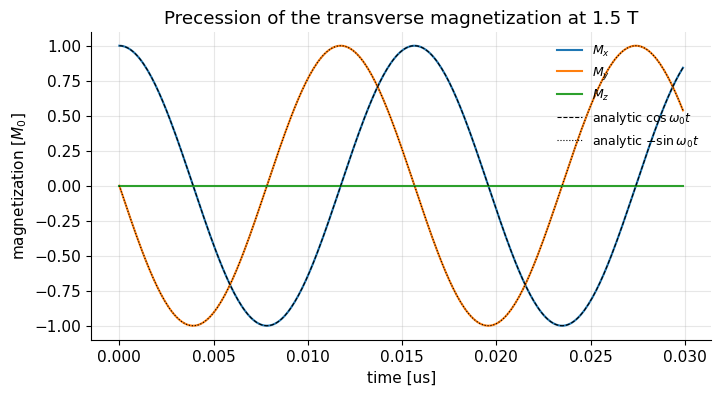

f0 = 63.87 MHz, period = 15.66 ns


In [2]:
# Free precession at 1.5 T (lab frame), port of the original cell
B0 = 1.5          # T
dt = 0.1e-9       # s  (0.1 ns -- the Larmor period at 1.5 T is only 15.7 ns!)
N = 300           # number of time steps
t, M = mt.bloch_simulate(n_steps=N-1, dt=dt, M_init=[1, 0, 0], B0=B0)   # M shape (N, 1, 3)

w0 = mt.GAMMA * B0
mt.plot_magnetization(t, M, time_unit="us", title="Precession of the transverse magnetization at 1.5 T")
plt.plot(t*1e6, np.cos(w0*t), "k--", lw=0.8, label=r"analytic $\cos\omega_0t$")
plt.plot(t*1e6, -np.sin(w0*t), "k:", lw=0.8, label=r"analytic $-\sin\omega_0t$")
plt.legend(loc="upper right", fontsize=9); plt.show()
print(f"f0 = {mt.larmor_frequency(B0)/1e6:.2f} MHz, period = {1/mt.larmor_frequency(B0)*1e9:.2f} ns")

Interpretation: in 30 ns, $\vec M$ completes about two turns; $M_x$ and $M_y$ are 90° out of phase ($M_y$ lags as $-\sin$: clockwise rotation) and $M_z=0$ throughout. The simulation and the formula coincide.

> **⚠️ Common confusion:** the original chapter's Python helper rotated $\vec M$ in the *right-handed* (counter-clockwise) sense, contradicting its own text ("left-handed"). In that code the RF field was also written rotating counter-clockwise, so the two errors cancelled. Here (and in `mri_tools`) everything is consistently left-handed: $M_{xy}\propto e^{-i\omega_0t}$. Physically the sense of rotation matters for, e.g., which circular polarization the RF coil must produce (Section 3.1) and the sign of frequency offsets in images.

## 3 RF excitation

**RF excitation** occurs when an oscillating magnetic field is applied perpendicular to the main field. If we apply RF at the Larmor frequency with a constant amplitude $B_1$, the lab-frame field is

$$\vec B(\vec r,t)=\begin{bmatrix}B_1\cos(\omega_0t)\\ -B_1\sin(\omega_0t)\\ B_0\end{bmatrix}$$

In words: a small field of strength $B_1$ that rotates in the $x$–$y$ plane at the Larmor frequency, in the same (clockwise) sense as the precession, on top of the large static $B_0$ along $z$.

where $\omega_0=\gamma B_0=2\pi\bar\gamma B_0$. (The original writes $+\sin$; with left-handed precession the co-rotating field needs $-\sin$, see the note above.) In complex notation, $B_x+iB_y=B_1e^{-i\omega_0t}$. When applied at the Larmor frequency, the RF field and the magnetization are in resonance and we achieve excitation.

### 3.1 Example: constant-amplitude ("hard") pulse

A good first RF pulse to consider is a constant amplitude, $B_1^+(\vec r,t)=B_1$, switched on for a duration $T_{rf}$. Applied on resonance, the Bloch equation produces a progressive rotation of $\vec M$ away from the $z$-axis while it keeps precessing:

![RF excitation in the lab frame](../images/RF_hard_lab_frame_on-resonance.gif)

*Lab frame: $\vec M$ spirals from the north pole down; the fast precession hides the simple tipping motion.*

> **🔧 Engineering reality:** a single linear coil produces an *oscillating* field $2B_1\cos(\omega_0t)\hat x$, which is the sum of two circularly polarized fields rotating in opposite directions, each of amplitude $B_1$. Only the co-rotating one, called $B_1^+$, tips the spins; the counter-rotating one ($B_1^-$) is off resonance by $2f_0$ and does (almost) nothing. That is why modern body coils are driven in **quadrature** (two channels 90° apart), producing a rotating field directly: this halves the required RF power (and SAR) compared to linear drive. (The tiny residual effect of the counter-rotating part is the Bloch–Siegert shift, demonstrated in Section 3.6.)

### 3.2 Lab frame versus rotating frame

For simplification we use the so-called **rotating frame**: a coordinate system that rotates around the $z$-axis at the RF frequency $\omega_{rf}$ (usually $=\omega_0=\gamma B_0$), in the same clockwise sense as the precession. The scanner-room coordinates are called the **lab frame** (or stationary frame).

> **🧭 Intuition:** stand on a merry-go-round that turns exactly as fast as the magnetization precesses. From there, a vector precessing at $\omega_0$ looks *stationary*—the effect of $B_0$ has vanished—and an RF field rotating at $\omega_0$ also looks stationary, a fixed field along (say) $x'$. In that frame the only remaining motion is the slow tipping of $\vec M$ around the RF field.

**The transformation.** Define the rotating-frame magnetization by "un-rotating" the lab-frame one:

$$M'_{xy}(t)=M_{xy}(t)\,e^{+i\omega_{rf}t},\qquad M'_z(t)=M_z(t)$$

In words: multiplying by $e^{+i\omega_{rf}t}$ rotates the transverse magnetization counter-clockwise by exactly the angle the frame has turned clockwise, so it undoes the frame's rotation.

Similarly, an RF field $B_x+iB_y=b_1(t)\,e^{-i\omega_{rf}t}$ in the lab becomes simply $b_1(t)$ in the rotating frame: the **complex envelope** $b_1(t)=B_{1,x}(t)+iB_{1,y}(t)$ of the RF pulse.

**Result** (derived step by step below): in the rotating frame, $\vec M'$ obeys the *same* Bloch equation, but with the field replaced by an **effective field**

$$\vec B_{eff}=\vec B'-\frac{\omega_{rf}}{\gamma}\hat z=\begin{bmatrix}B_{1,x}(t)\\B_{1,y}(t)\\B_0+\Delta B_0(\vec r)-\omega_{rf}/\gamma\end{bmatrix}$$

In words: going into a frame that rotates at $\omega_{rf}$ is equivalent to subtracting a fictitious field $\omega_{rf}/\gamma$ along $z$, and the RF field becomes a fixed (or slowly varying) vector.

where $\vec B'$ is the lab field expressed in rotating coordinates, $\hat z$ the unit vector along $z$, and $\Delta B_0(\vec r)$ any deviation of the static field (inhomogeneity, susceptibility, chemical shift, gradients). On resonance, $\omega_{rf}=\omega_0=\gamma B_0$, so **$B_0$ disappears** from the $z$-component exactly. Off resonance, the $z$-component is

$$B_{eff,z}=\frac{\omega_0-\omega_{rf}}{\gamma}+\Delta B_0=\frac{\Delta\omega}{\gamma}+\Delta B_0$$

In words: only the *mismatch* between the spins' precession frequency and the frame frequency survives, expressed as an equivalent field $\Delta\omega/\gamma$ (e.g. 100 Hz off-resonance ↔ $100/42.58\times10^6$ T = 2.3 µT).

<details><summary><b>📐 Derivation (optional): the rotating-frame Bloch equation</b></summary>

Ignore relaxation (it acts on $M_{xy}$ and $M_z$ the same way in both frames because the frame rotation doesn't change lengths or $M_z$). Write the precession term in complex form. With $b=B_x+iB_y$ (lab) and the component formulas of Section 1.1:

$$\frac{dM_{xy}}{dt}=\gamma(M_yB_z-M_zB_y)+i\gamma(M_zB_x-M_xB_z)=-i\gamma B_z\,M_{xy}+i\gamma M_z\,b,$$

$$\frac{dM_z}{dt}=\gamma(M_xB_y-M_yB_x)=\gamma\,\mathrm{Im}\{M_{xy}^*\,b\}.$$

(Check the first by expanding: $-i\gamma B_z(M_x+iM_y)=\gamma B_zM_y-i\gamma B_zM_x$ and $i\gamma M_z(B_x+iB_y)=-\gamma M_zB_y+i\gamma M_zB_x$.)

Now substitute $M'_{xy}=M_{xy}e^{i\omega_{rf}t}$ and $b'=b\,e^{i\omega_{rf}t}$. By the product rule,

$$\frac{dM'_{xy}}{dt}=e^{i\omega_{rf}t}\frac{dM_{xy}}{dt}+i\omega_{rf}M'_{xy}=-i\gamma B_zM'_{xy}+i\gamma M_zb'+i\omega_{rf}M'_{xy}=-i\gamma\Big(B_z-\frac{\omega_{rf}}{\gamma}\Big)M'_{xy}+i\gamma M_z\,b'.$$

For $M_z$: $M_{xy}^*b=(M'_{xy}e^{-i\omega_{rf}t})^*\,b'e^{-i\omega_{rf}t}=M'^*_{xy}\,b'$, so $dM_z/dt=\gamma\,\mathrm{Im}\{M'^*_{xy}b'\}$ is unchanged.

Comparing with the lab-frame equations, the rotating-frame equations are *identical in form*, with $b\to b'$ and $B_z\to B_z-\omega_{rf}/\gamma$. That is the statement $d\vec M'/dt=\gamma\vec M'\times\vec B_{eff}$ with $\vec B_{eff}=[\mathrm{Re}\,b',\mathrm{Im}\,b',B_z-\omega_{rf}/\gamma]^T$. For RF applied as $b=b_1(t)e^{-i\omega_{rf}t}$ we get $b'=b_1(t)$.

In vector language (for readers who know it): in a frame rotating with angular velocity $\vec\Omega$, $(d\vec M/dt)_{rot}=(d\vec M/dt)_{lab}-\vec\Omega\times\vec M$. Our frame rotates clockwise, $\vec\Omega=-\omega_{rf}\hat z$, so $(d\vec M/dt)_{rot}=\gamma\vec M\times\vec B+\vec M\times\vec\Omega=\gamma\vec M\times(\vec B-\tfrac{\omega_{rf}}{\gamma}\hat z)$.

</details>

Now RF excitation is simply a rotation around the (fixed) RF field, and we no longer need the Larmor frequency in our analysis:

![RF excitation in the rotating frame](../images/RF_hard_rotating_frame_on-resonance.gif)

*Rotating frame: the same pulse is a simple rotation of $\vec M$ about the RF field direction.*

| ![90-degree flip, lab frame](../images/RF_90_flip_lab_frame.gif) | ![90-degree flip, rotating frame](../images/RF_90_flip_rotating_frame.gif) |
| :-: | :-: |
| 90° flip seen in the lab frame | the same 90° flip seen in the rotating frame |

> **🔧 Engineering reality:** the rotating frame is not just a mathematical trick—the receiver does it in hardware. Demodulation (mixing the received signal with a reference oscillator at $f_{rf}$) removes the $e^{-i\omega_0t}$ carrier exactly like the $e^{+i\omega_{rf}t}$ factor above; see [C2](../pass2_deep_dive/C2_MRI_Signal_Equation.ipynb) and [B5](../pass2_deep_dive/B5_RF_System_and_Receive_Chain.ipynb). The transmitter does the reverse: a digital waveform $b_1(t)$ is mixed *up* to $f_{rf}$.

### 3.3 Python: non-resonant, resonant, and rotating-frame excitation (port of the original cells)

First, a **non-resonant** field: an additional *static* field $B_1$ along $x$, orthogonal to $B_0$ but *not* oscillating at the Larmor frequency. Then the same amplitude rotating **at the Larmor frequency**, $\omega_0=\gamma B_0$. Finally the resonant case computed directly **in the rotating frame**. As in the original, we use $B_0=10$ mT ($f_0=426$ kHz) to keep the number of time steps manageable, and choose $B_1$ for a 90° flip in $T_{rf}=1$ ms.

f0 = 425.8 kHz, B1 = 5.87 uT  (= 0.059 % of B0)


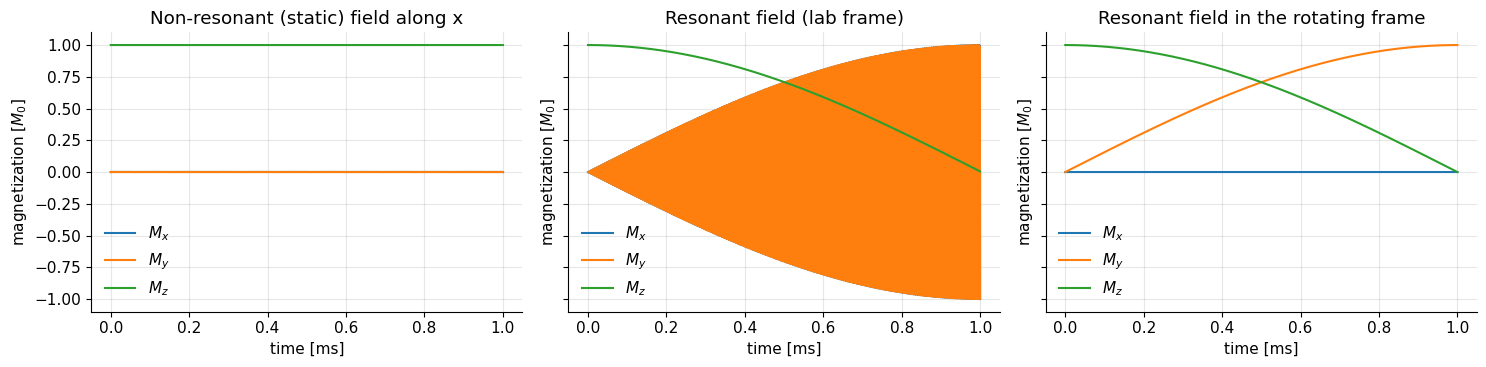

In [3]:
# Parameters (SI units). Original used mT and ms; here: tesla and seconds.
B0 = 10e-3                          # T  (10 mT, a "toy" field so the lab-frame simulation is feasible)
f0 = mt.larmor_frequency(B0)        # Hz (~425.8 kHz)
T_RF = 1e-3                         # s
Nt = 10000                          # time steps (dt = 0.1 us, ~23 steps per Larmor period)
dt = T_RF / Nt
t_rf = np.arange(Nt) * dt
flip = np.pi / 2
B10 = mt.b1_for_flip(flip, T_RF)    # T, amplitude giving a 90-degree flip: flip / (gamma * T_RF)
print(f"f0 = {f0/1e3:.1f} kHz, B1 = {B10*1e6:.2f} uT  (= {B10/B0*100:.3f} % of B0)")

experiments = {
    "Non-resonant (static) field along x": dict(B1=np.full(Nt, B10, complex), B0=B0),
    "Resonant field (lab frame)":          dict(B1=B10*np.exp(-1j*2*np.pi*f0*t_rf), B0=B0),
    "Resonant field in the rotating frame": dict(B1=np.full(Nt, B10, complex), B0=0.0),
}
fig, axs = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
results = {}
for ax, (name, kw) in zip(axs, experiments.items()):
    t, M = mt.bloch_simulate(dt=dt, **kw)
    results[name] = M[:, 0, :]
    mt.plot_magnetization(t, M, ax=ax, title=name)
plt.tight_layout(); plt.show()

Interpretation: (left) a static transverse field of only 0.06 % of $B_0$ just tilts the precession axis by 0.03°, so $M_x,M_y$ stay ≈ 0 and $M_z\approx1$—no excitation. (middle) The resonant field tips $\vec M$ to the transverse plane: $M_z$ goes from 1 to 0 in 1 ms, while $M_x$ and $M_y$ oscillate 426 000 times per second (an unreadable band). (right) In the rotating frame the same physics is a smooth quarter-turn: $M_z=\cos(\gamma B_1t)$, $M_y=\sin(\gamma B_1t)$. It is hard to visualize $M_{xy}$ in the lab because it is rotating at the Larmor frequency; the rotating frame makes excitation clear.

The next cell checks the claim of Section 3.2 numerically: take the lab-frame result, multiply $M_{xy}$ by $e^{+i\omega_0t}$, and compare with the rotating-frame simulation. With a still smaller toy field ($f_0=5$ kHz) we can also *see* the spiral in 3D.

max |M'_xy(from lab) - M_xy(rotating sim)| = 1.3e-01  (limited by the finite time step)


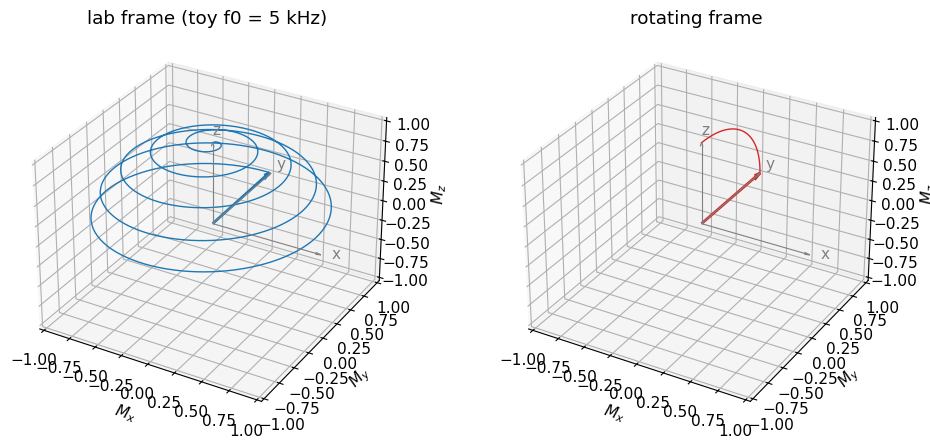

In [4]:
# (a) Check: lab-frame result transformed into the rotating frame == rotating-frame simulation
M_lab = results["Resonant field (lab frame)"]
M_rot = results["Resonant field in the rotating frame"]
t = np.arange(Nt + 1) * dt
Mxy_lab_to_rot = (M_lab[:, 0] + 1j*M_lab[:, 1]) * np.exp(+1j*2*np.pi*f0*t)
err = np.max(np.abs(Mxy_lab_to_rot - (M_rot[:, 0] + 1j*M_rot[:, 1])))
print(f"max |M'_xy(from lab) - M_xy(rotating sim)| = {err:.1e}  (limited by the finite time step)")

# (b) Toy field f0 = 5 kHz so that the lab-frame spiral is visible; same 90-degree pulse
f0_toy = 5e3; B0_toy = f0_toy / mt.GAMMA_BAR
dt2 = 1e-6; t2 = np.arange(int(T_RF/dt2)) * dt2
_, M_l = mt.bloch_simulate(B1=B10*np.exp(-1j*2*np.pi*f0_toy*t2), dt=dt2, B0=B0_toy)
_, M_r = mt.bloch_simulate(B1=np.full(len(t2), B10, complex), dt=dt2)
fig = plt.figure(figsize=(10, 4.5))
mt.plot_magnetization_3d(M_l[:, 0], ax=fig.add_subplot(1, 2, 1, projection="3d"), title="lab frame (toy f0 = 5 kHz)")
mt.plot_magnetization_3d(M_r[:, 0], ax=fig.add_subplot(1, 2, 2, projection="3d"), title="rotating frame", color="C3")
plt.tight_layout(); plt.show()

Interpretation: the two simulations agree to about 0.1 of $M_0$. The residual is a numerical artifact of the lab-frame run: the RF field rotates by ~16° per 0.1 µs step but is held constant within each step; the difference shrinks with smaller steps—another reason to simulate in the rotating frame.

> **TODO (polish):** sample the lab-frame RF at step mid-points (or use smaller steps) to show the agreement converging. In 3D, the lab-frame tip of $\vec M$ spirals down five times around $z$ (one turn per 0.2 ms), while in the rotating frame it simply moves along a quarter circle in the $y$–$z$ plane, from $+z$ to $+y$.

### 3.4 Flip angle and common hard pulses

In the rotating frame (on resonance) the magnetization rotates about $b_1$ at angular speed $\gamma|b_1(t)|$. The total angle—the **flip angle**—is therefore the accumulated rotation:

$$\theta=\gamma\int_0^{T_{rf}}|b_1(t)|\,dt\qquad\xrightarrow{\ b_1=B_1\text{ constant}\ }\qquad\theta=\gamma\,B_1\,T_{rf}$$

In words: the flip angle is the gyromagnetic ratio times the area under the RF amplitude envelope; for a rectangular ("hard") pulse it is amplitude × duration.

where $b_1(t)$ [T] is the RF envelope (rotating frame), $T_{rf}$ [s] the pulse duration, $\theta$ [rad]. (This simple form assumes the RF phase is constant during the pulse and the spins are on resonance.) Example: a 90° ($\pi/2$) pulse in 1 ms needs $B_1=\frac{\pi/2}{2.675\times10^8\times10^{-3}}=5.87$ µT; in 0.2 ms, 29.4 µT.

**Which way does $\vec M$ tip?** The rotation is (left-handed) about the direction of $b_1$, which is set by the RF **phase** $\phi_{rf}$: $b_1=B_1e^{i\phi_{rf}}$. Starting from $+z$:

| RF phase $\phi_{rf}$ | $b_1$ along | after a 90° pulse $\vec M$ points along |
|---|---|---|
| 0° | $+x'$ | $+y'$ |
| 90° | $+y'$ | $-x'$ |
| 180° | $-x'$ | $-y'$ |
| −90° | $-y'$ | $+x'$ |

(Check with the cross product: $\hat z\times\hat x=+\hat y$, so $d\vec M/dt\propto+\hat y$ for $b_1$ along $x$.)

| ![RF 45-degree flip](../images/RF_45flip.gif) | ![RF 90-degree flip](../images/RF_90flip.gif) | ![RF 180-degree flip](../images/RF_180flip.gif) |
| :-: | :-: | :-: |
| 45° flip | 90° flip | 180° flip (inversion) |

 45 deg pulse: B1 =  2.94 uT, final M = [0.    0.707 0.707]
 90 deg pulse: B1 =  5.87 uT, final M = [0. 1. 0.]
180 deg pulse: B1 = 11.74 uT, final M = [ 0.  0. -1.]


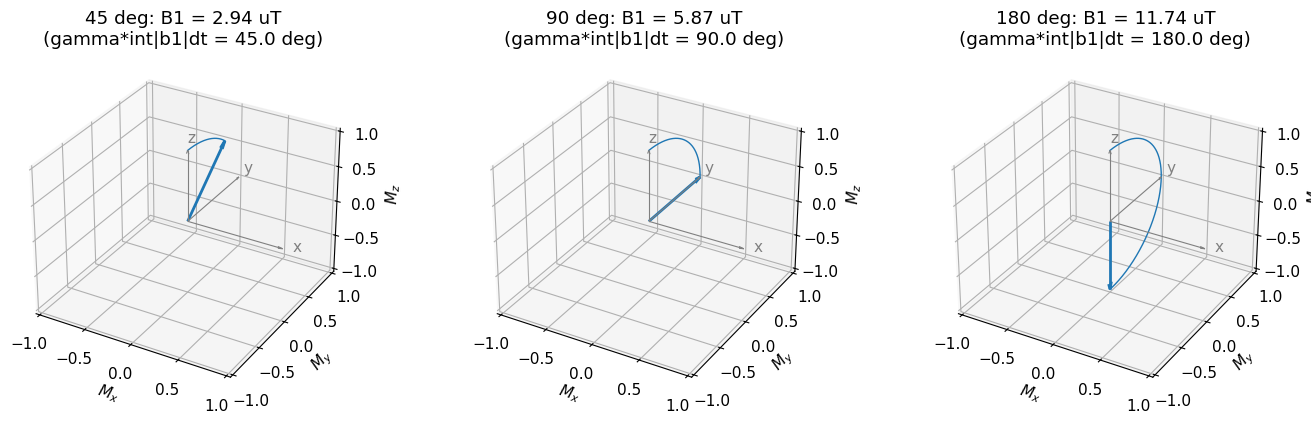

In [5]:
# Hard pulses of 45, 90 and 180 degrees, duration 1 ms, rotating frame, on resonance
T_rf, dt = 1e-3, 2e-6
n = int(T_rf / dt)
fig = plt.figure(figsize=(14, 4.2))
for j, deg in enumerate([45, 90, 180]):
    B1 = mt.b1_for_flip(np.deg2rad(deg), T_rf)          # T
    b1 = np.full(n, B1, complex)                         # phase 0 -> along x'
    t, M = mt.bloch_simulate(B1=b1, dt=dt)
    th = np.rad2deg(mt.flip_angle(b1, dt))
    ax = fig.add_subplot(1, 3, j+1, projection="3d")
    mt.plot_magnetization_3d(M[:, 0], ax=ax, title=f"{deg} deg: B1 = {B1*1e6:.2f} uT\n(gamma*int|b1|dt = {th:.1f} deg)")
    print(f"{deg:3d} deg pulse: B1 = {B1*1e6:5.2f} uT, final M = {np.round(M[-1, 0], 3)}")
plt.tight_layout(); plt.show()

Interpretation: all three trajectories are arcs in the $y$–$z$ plane; the 45° pulse leaves $M_z=0.707$, $M_y=0.707$; the 90° pulse puts all magnetization along $+y'$; the 180° pulse inverts it to $-z$ (no transverse magnetization, hence no signal). Doubling the amplitude doubles the flip angle.

Again, open the [Bloch Equation Simulator](https://www.drcmr.dk/BlochSimulator/) to explore:
1. *Lab versus rotating frame:* the default view is the lab (stationary) frame. Select 'B0' under 'Frame' (top left) to change to the rotating frame.
1. *RF excitation:* choose the 'Equilibrium' scene (bottom left), then use the '90x hard' button to apply a constant-amplitude pulse.
1. *Other flip angles:* go back to 'Equilibrium' and try the other hard-pulse flip angles.

> **🔧 Engineering reality:** the peak $B_1$ of a whole-body transmit coil is limited to roughly 15–25 µT by the RF amplifier (tens of kW) and by SAR (tissue heating ∝ $B_1^2$, and at fixed flip angle ∝ $B_0^2$). A 90° hard pulse therefore takes at least ~0.25–0.4 ms. Because SAR ∝ $\int B_1^2dt\propto\theta^2/T_{rf}$, a 180° pulse deposits 4× the energy of a 90° pulse of the same duration—one reason fast spin-echo sequences hit SAR limits at 3 T ([B6](../pass2_deep_dive/B6_MRI_Safety.ipynb)).

### 3.5 Off-resonant excitation: the tilted effective field

If the spins precess at $\omega_0+\Delta\omega$ while the RF (and our frame) rotates at $\omega_{rf}$, the effective field from Section 3.2 has a $z$-component (here written with $\Delta f$ = spin frequency minus RF frequency):

$$\vec B_{eff}=\begin{bmatrix}B_1\\0\\ \Delta f/\bar\gamma\end{bmatrix},\qquad |\vec B_{eff}|=\sqrt{B_1^2+(\Delta f/\bar\gamma)^2},\qquad \tan\alpha=\frac{\bar\gamma B_1}{\Delta f}$$

In words: off resonance, the field the spins see in the rotating frame is tilted away from the transverse plane towards $z$ by an angle $\alpha$ measured from the $z$-axis, and is stronger than $B_1$ alone.

where $\alpha$ [rad] is the angle between $\vec B_{eff}$ and $z$ ($\alpha=90°$ on resonance). $\vec M$ now rotates around this *tilted* axis on a cone, at rate $\omega_{eff}=\gamma|\vec B_{eff}|=2\pi\sqrt{(\bar\gamma B_1)^2+\Delta f^2}$. Starting from $+z$, it can never get further than $2\alpha$ from the $z$-axis; one finds

$$M_z(t)=\cos^2\alpha+\sin^2\alpha\,\cos(\omega_{eff}t)$$

In words: the longitudinal magnetization oscillates between 1 and $\cos2\alpha$; far off resonance ($\alpha\to0$), it hardly moves at all.

This is the formula used for the resonance curve in [A1](../pass2_deep_dive/A1_Spin_Physics.ipynb).

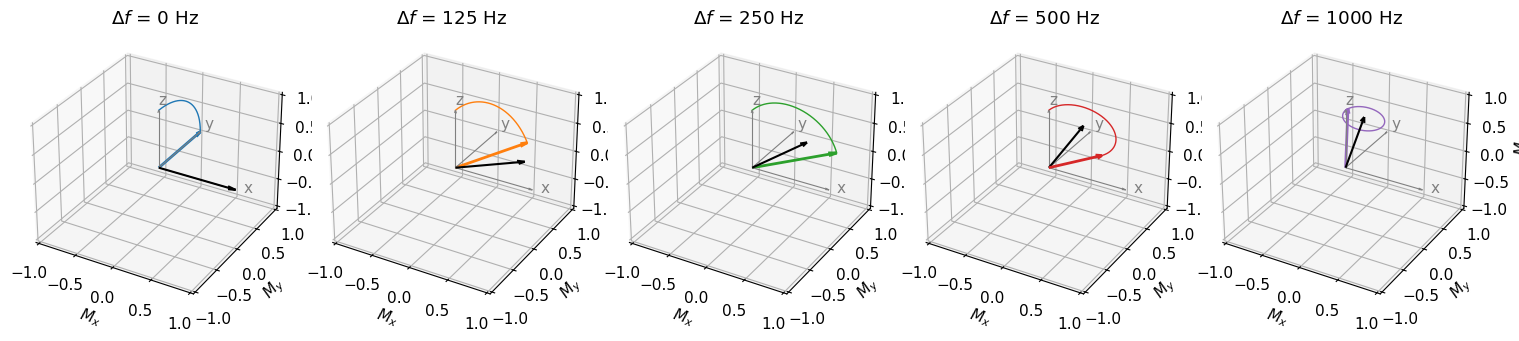

In [6]:
# 90-degree hard pulse (1 ms, gamma_bar*B1 = 250 Hz) for spins at different off-resonance
T_rf, dt = 1e-3, 2e-6
n = int(T_rf / dt)
B1 = mt.b1_for_flip(np.pi/2, T_rf)
offsets = [0, 125, 250, 500, 1000]                       # Hz
t, M = mt.bloch_simulate(B1=np.full(n, B1, complex), dt=dt, df=offsets)   # one simulation, 5 spins
fig = plt.figure(figsize=(15, 3.6))
for j, f in enumerate(offsets):
    ax = fig.add_subplot(1, 5, j+1, projection="3d")
    mt.plot_magnetization_3d(M[:, j], ax=ax, title=f"$\\Delta f$ = {f} Hz", color=f"C{j}")
    Beff = np.array([B1, 0, f / mt.GAMMA_BAR]); Beff /= np.linalg.norm(Beff)
    ax.quiver(0, 0, 0, *Beff, color="k", lw=1.5, arrow_length_ratio=0.1)   # direction of B_eff
plt.tight_layout(); plt.show()

Interpretation: the black arrow is $\vec B_{eff}$. On resonance (left) the pulse reaches the transverse plane. As $\Delta f$ grows, $\vec B_{eff}$ tilts towards $z$, the cone shrinks and the rotation speeds up; at 1 kHz, $\vec M$ makes a full small circle and ends close to where it started. A hard pulse only excites spins within about $\pm\bar\gamma B_1$ of the RF frequency.

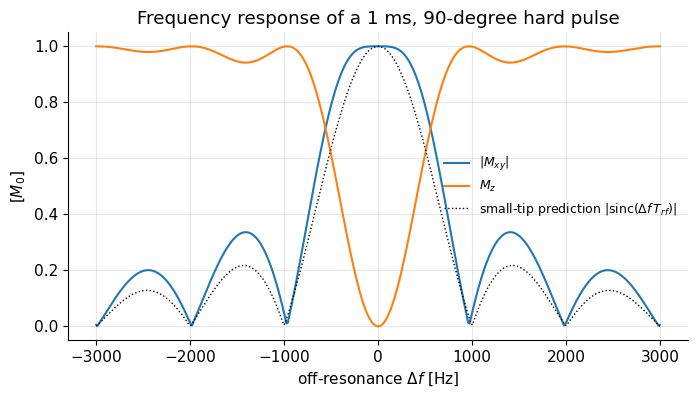

In [7]:
# Excitation profile: |Mxy| and Mz after the 90-degree hard pulse versus off-resonance
dfs = np.linspace(-3000, 3000, 401)
_, Mend = mt.bloch_simulate(B1=np.full(n, B1, complex), dt=dt, df=dfs, return_all=False)
plt.plot(dfs, np.abs(Mend[:, 0] + 1j*Mend[:, 1]), label=r"$|M_{xy}|$")
plt.plot(dfs, Mend[:, 2], label=r"$M_z$")
plt.plot(dfs, np.abs(np.sinc(dfs * T_rf)), "k:", lw=1, label=r"small-tip prediction $|\mathrm{sinc}(\Delta f\,T_{rf})|$")
plt.xlabel(r"off-resonance $\Delta f$ [Hz]"); plt.ylabel(r"[$M_0$]")
plt.title("Frequency response of a 1 ms, 90-degree hard pulse"); plt.legend(fontsize=9); plt.show()

Interpretation: the excited band is about 1 kHz wide (≈ $1/T_{rf}$). Its shape resembles a sinc—the Fourier transform of the rectangular pulse (dotted)—an approximation that becomes exact for small flip angles. This link between pulse shape and frequency response is the topic of [E1 RF Pulses](../pass2_deep_dive/E1_RF_Pulses.ipynb).

### 3.6 Linear versus circular RF drive ($B_1^+$)

Earlier we claimed that a linearly oscillating field $2B_1\cos(\omega_0 t)\hat x$ excites just like a rotating field of amplitude $B_1$. The lab-frame simulation below (toy $f_0=5$ kHz so that $B_1/B_0$ is not negligible) checks this.

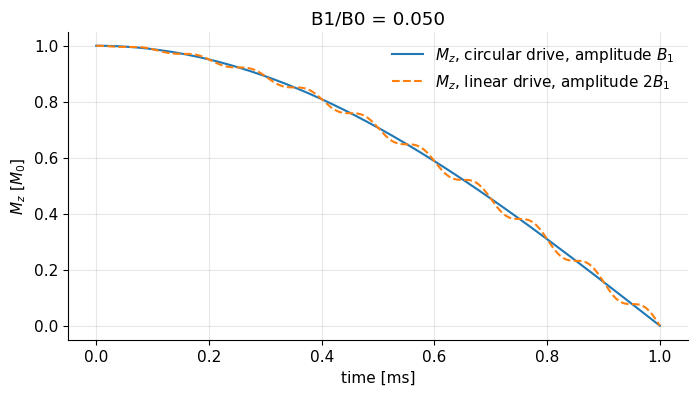

final Mz: circular 0.000, linear 0.000


In [8]:
# Circularly polarized drive (B1 e^{-i w0 t}) versus linear drive (2 B1 cos(w0 t) along x), lab frame
f0_toy = 5e3; B0_toy = f0_toy / mt.GAMMA_BAR
dt3 = 0.5e-6; t3 = np.arange(int(T_RF/dt3)) * dt3
B1 = mt.b1_for_flip(np.pi/2, T_RF)
_, Mc = mt.bloch_simulate(B1=B1*np.exp(-1j*2*np.pi*f0_toy*t3), dt=dt3, B0=B0_toy)
_, Ml = mt.bloch_simulate(B1=(2*B1*np.cos(2*np.pi*f0_toy*t3)).astype(complex), dt=dt3, B0=B0_toy)
tt = np.arange(len(t3) + 1) * dt3
plt.plot(tt*1e3, Mc[:, 0, 2], label=r"$M_z$, circular drive, amplitude $B_1$")
plt.plot(tt*1e3, Ml[:, 0, 2], "--", label=r"$M_z$, linear drive, amplitude $2B_1$")
plt.xlabel("time [ms]"); plt.ylabel(r"$M_z$ [$M_0$]"); plt.legend(); plt.title(f"B1/B0 = {B1/B0_toy:.3f}"); plt.show()
print(f"final Mz: circular {Mc[-1,0,2]:.3f}, linear {Ml[-1,0,2]:.3f}")

Interpretation: both drives give a 90° flip; the linear one shows small wiggles at $2f_0$ and a tiny error (Bloch–Siegert effect, ∝ $(B_1/B_0)^2$), utterly negligible at clinical fields where $B_1/B_0\sim10^{-6}$. But the linear drive needs twice the amplitude—and the counter-rotating half just heats the patient.

## 4 Relaxation

The other key result of the Bloch equation is that the magnetization returns to equilibrium with the time constants $T_1$ and $T_2$. In the rotating frame, on resonance and with no RF ($\vec B_{eff}=0$), the precession term vanishes and the Bloch equation simplifies to

$$
\frac{d\vec{M}(\vec{r},t)}{dt} =
\begin{bmatrix}
-1/T_2(\vec{r})& 0 & 0 \\
0 & -1/T_2(\vec{r}) & 0 \\
0 & 0 & -1/T_1(\vec{r})
\end{bmatrix}
\vec{M}(\vec{r},t)
+
\begin{bmatrix}
 0 \\
 0 \\
M_0(\vec{r})/T_1(\vec{r})
\end{bmatrix}
$$

In words: each component relaxes independently—$M_x$ and $M_y$ towards 0 with $T_2$, $M_z$ towards $M_0$ with $T_1$.

### 4.1 Solving the three equations

*Transverse:* $dM_x/dt=-M_x/T_2$ is the standard decay ODE $dy/dt=-y/\tau$, solution $M_x(t)=M_x(0)e^{-t/T_2}$; the same for $M_y$, so in complex notation

$$M_{xy}(\vec r,t)=M_{xy}(\vec r,0)\,e^{-t/T_2(\vec r)}$$

In words: the transverse magnetization decays from its value at $t=0$ to 0 with exponential time constant $T_2$; after $t=T_2$, 37 % is left.

*Longitudinal:* $dM_z/dt=-(M_z-M_0)/T_1$. Substitute $u=M_z-M_0$ (the distance from equilibrium); since $M_0$ is constant, $du/dt=dM_z/dt=-u/T_1$, so $u(t)=u(0)e^{-t/T_1}$. Back-substituting:

$$M_z(\vec r,t)=M_z(\vec r,0)\,e^{-t/T_1(\vec r)}+M_0(\vec r)\big(1-e^{-t/T_1(\vec r)}\big)$$

In words: the longitudinal magnetization recovers to its equilibrium $M_0$ with time constant $T_1$; the initial value is "forgotten" exponentially and replaced by $M_0$.

In matrix form, as in the original:

$$
\vec{M}(\vec{r},t) =
\begin{bmatrix}
e^{-t/T_2(\vec{r})} & 0 & 0 \\
0 & e^{-t/T_2(\vec{r})} & 0 \\
0 & 0 & e^{-t/T_1(\vec{r})}
\end{bmatrix}
\vec{M}(\vec{r},0)
+
\begin{bmatrix}
 0 \\
 0 \\
M_0(\vec{r})(1-e^{-t/T_1(\vec{r})})
\end{bmatrix}
$$

In words: relaxation over a time $t$ multiplies each component by its decay factor and adds back a fraction of $M_0$ to $M_z$.

(The original prints a 1 in the bottom-right matrix entry; it must be $e^{-t/T_1}$, as the component formula shows.)

It is extremely convenient to split $\vec M$ into the **transverse** ($xy$) and **longitudinal** ($z$) components: the longitudinal component is by convention aligned with $B_0$, the transverse components are perpendicular to it. Only the transverse part produces signal; only the longitudinal part is "stored" for the next excitation.

Special cases worth remembering:
* After a 90° pulse ($M_z(0)=0$): $M_z(t)=M_0(1-e^{-t/T_1})$ — 63 % recovered after $T_1$, 95 % after $3T_1$, 99 % after $5T_1$.
* After a 180° pulse ($M_z(0)=-M_0$): $M_z(t)=M_0(1-2e^{-t/T_1})$, which crosses zero at $t=T_1\ln2\approx0.69\,T_1$ (the basis of fat/fluid suppression by inversion recovery, [D1](../pass2_deep_dive/D1_Basic_Contrast_Mechanisms.ipynb)).

**T1 and T2 relaxation after RF excitation**

![Relaxation T1 and T2](../images/relaxation_t1t2.gif)

### 4.2 Simulation of relaxation

One more time, open the [Bloch Equation Simulator](https://www.drcmr.dk/BlochSimulator/). Under 'Relaxation' (top left) you can adjust the $T_1$ and $T_2$ relaxation *times*:
1. Experiment with different $T_1$ and $T_2$ values.
1. When the magnetization has returned to equilibrium, apply an RF pulse and you will see relaxation occurring again.
1. From equilibrium, try a 180° flip angle and adjust both $T_1$ and $T_2$. Which parameter influences the relaxation in this situation? (Answer in the Python cell below.)

The next cell is a port of the original code: a 1 ms hard pulse followed by exact relaxation (`mt.relax`), for 90° and for 180°. In the original code the pulse tipped $\vec M$ to $+x$ (equivalent to RF phase −90° in our convention); here we use RF phase −90° as well, so the plots match the original.

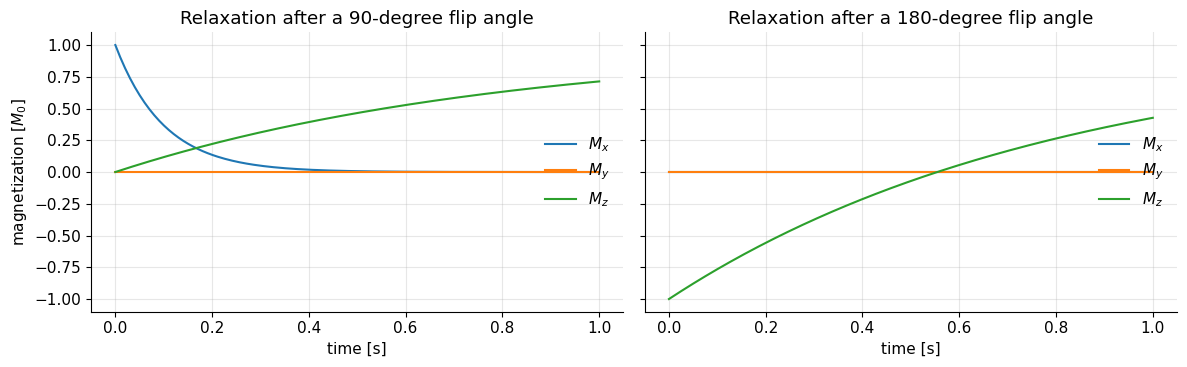

In [9]:
# Relaxation after a 90- and a 180-degree hard pulse (rotating frame), port of the original cell
M0, T1, T2 = 1.0, 0.8, 0.1                  # s
t = np.linspace(0, 1, 200)                  # s
T_pulse = 1e-3                              # s
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, flip_deg in zip(axs, [90, 180]):
    B1 = mt.b1_for_flip(np.deg2rad(flip_deg), T_pulse)
    b1 = np.full(200, B1 * np.exp(-1j*np.pi/2))           # RF phase -90 deg -> b1 along -y -> M tips to +x
    _, M_start = mt.bloch_simulate(B1=b1, dt=T_pulse/200, return_all=False)
    M_start = M_start[0]                                   # relaxation during the 1 ms pulse neglected
    Mall = np.array([mt.relax(M_start, ti, T1, T2, M0) for ti in t])
    ax.plot(t, Mall[:, 0], label=r"$M_x$"); ax.plot(t, Mall[:, 1], label=r"$M_y$"); ax.plot(t, Mall[:, 2], label=r"$M_z$")
    ax.set_xlabel("time [s]"); ax.set_title(f"Relaxation after a {flip_deg}-degree flip angle"); ax.legend(loc="center right")
axs[0].set_ylabel(r"magnetization [$M_0$]"); plt.tight_layout(); plt.show()

Interpretation: after 90°, $M_x$ decays with $T_2=100$ ms while $M_z$ recovers with $T_1=0.8$ s. After 180°, there is no transverse magnetization at all, so **only $T_1$ matters**: $M_z$ recovers from −1 through zero at $T_1\ln2=0.55$ s.

### 4.3 Everything at once: excitation, precession and relaxation

In real life all terms act together. Below: a 90° pulse, then free evolution for 300 ms in the rotating frame with an off-resonance of $\Delta f=10$ Hz (so $\vec M$ slowly precesses in the rotating frame) and $T_1=300$ ms, $T_2=60$ ms.

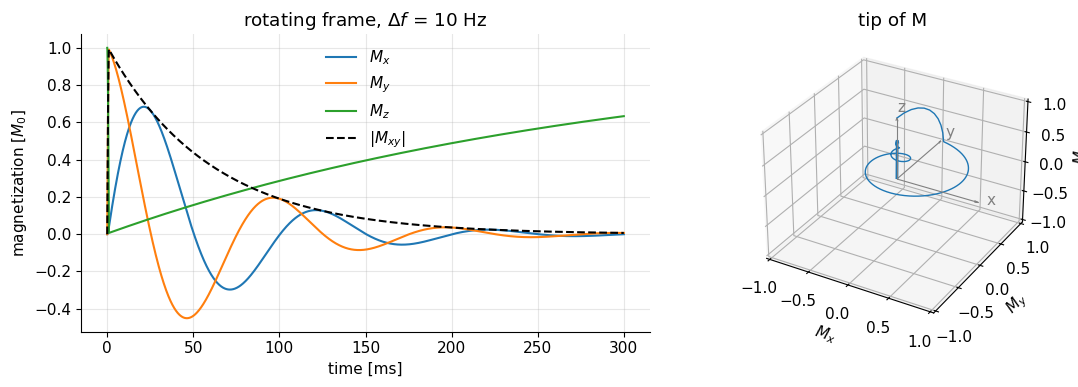

In [10]:
# 90-degree pulse followed by free precession + relaxation, off-resonance 10 Hz (rotating frame)
dt = 1e-4                                                  # s
b1 = np.zeros(3000, complex)
b1[:10] = mt.b1_for_flip(np.pi/2, 10*dt)                  # 1 ms hard pulse at the start
t, M = mt.bloch_simulate(B1=b1, dt=dt, df=10.0, T1=0.3, T2=0.06)
fig = plt.figure(figsize=(12, 4))
mt.plot_magnetization(t, M, ax=fig.add_subplot(1, 2, 1), components="xyza", title=r"rotating frame, $\Delta f$ = 10 Hz")
mt.plot_magnetization_3d(M[:, 0], ax=fig.add_subplot(1, 2, 2, projection="3d"), title="tip of M")
plt.tight_layout(); plt.show()

Interpretation: in the rotating frame the residual 10 Hz off-resonance makes $M_x,M_y$ oscillate slowly (one turn per 100 ms) inside the decaying envelope $|M_{xy}|=e^{-t/T_2}$, while $M_z$ recovers; the 3D tip traces a spiral that climbs back to the north pole.

## 5 How the numerical Bloch simulator works

`mt.bloch_simulate` (and the original's `bloch_rotate`) solve the Bloch equation by **operator splitting** in small time steps $\Delta t$, treating the field as constant within each step:

1. **Rotate:** for constant $\vec B$, the precession term alone is solved *exactly* by a rotation of $\vec M$ about $\vec B$ by the angle $\gamma|\vec B|\Delta t$ (left-handed). The rotation matrix comes from Rodrigues' formula ([RM2](../refreshers/RM2_Complex_Numbers_and_Rotations.ipynb)).
2. **Relax:** the relaxation terms alone are solved *exactly* by the formulas of Section 4.1 with $t=\Delta t$.
3. Repeat for the next time step.

Each sub-step is exact; the only approximation is that rotation and relaxation are applied one after the other instead of simultaneously, and that $\vec B$ is held constant during $\Delta t$. The error per step is ∝ $\Delta t^2$, so the total error after a fixed time is ∝ $\Delta t$ ("first-order" method). See [RM1](../refreshers/RM1_ODEs_for_MRI.ipynb) for numerical stepping of ODEs in general.

Below, a **minimal stepper** (written out so you can see every operation) is compared with `mt.bloch_simulate` and with a high-accuracy general-purpose ODE solver (`scipy.integrate.solve_ivp`), for a case where rotation and relaxation interact strongly: an off-resonant pulse with very short relaxation times.

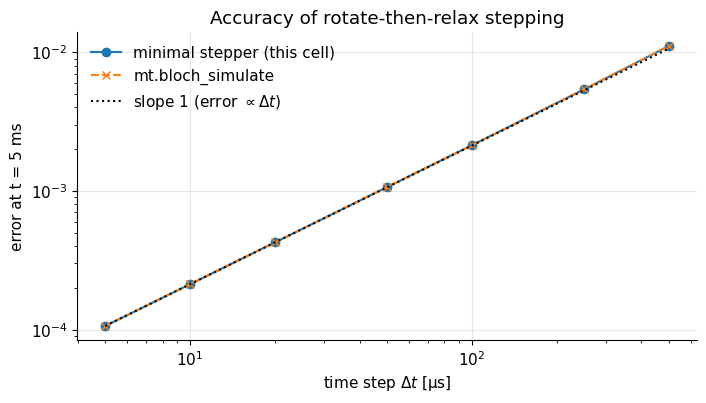

reference (solve_ivp) M(5 ms) = [ 0.1771 -0.0663  0.6148]


In [11]:
from scipy.integrate import solve_ivp

def bloch_step_minimal(M, B, dt, T1, T2, M0=1.0, gamma=mt.GAMMA):
    """One rotate-then-relax step. M, B: arrays (3,). Units: T, s."""
    Bn = np.linalg.norm(B)
    if Bn > 0:
        n = B / Bn                         # unit rotation axis
        phi = -gamma * Bn * dt             # minus sign: left-handed rotation
        M = M*np.cos(phi) + np.cross(n, M)*np.sin(phi) + n*np.dot(n, M)*(1 - np.cos(phi))   # Rodrigues
    E1, E2 = np.exp(-dt/T1), np.exp(-dt/T2)
    return np.array([M[0]*E2, M[1]*E2, M0 + (M[2] - M0)*E1])

# Test problem (rotating frame): constant b1 along x, off-resonance 300 Hz, T1 = 20 ms, T2 = 5 ms, 5 ms total
B1, df, T1, T2, T_end = mt.b1_for_flip(np.pi/2, 1e-3), 300.0, 0.02, 0.005, 5e-3
Bvec = np.array([B1, 0.0, df / mt.GAMMA_BAR])

def bloch_rhs(t, M):                       # the full Bloch equation, right-hand side
    return mt.GAMMA*np.cross(M, Bvec) + np.array([-M[0]/T2, -M[1]/T2, -(M[2] - 1.0)/T1])
ref = solve_ivp(bloch_rhs, (0, T_end), [0, 0, 1], rtol=1e-11, atol=1e-12).y[:, -1]

steps = np.array([5e-6, 1e-5, 2e-5, 5e-5, 1e-4, 2.5e-4, 5e-4])
err_min, err_mt = [], []
for h in steps:
    M = np.array([0.0, 0.0, 1.0])
    for _ in range(int(round(T_end/h))):
        M = bloch_step_minimal(M, Bvec, h, T1, T2)
    err_min.append(np.linalg.norm(M - ref))
    _, Mm = mt.bloch_simulate(B1=np.full(int(round(T_end/h)), B1, complex), dt=h, df=df, T1=T1, T2=T2, return_all=False)
    err_mt.append(np.linalg.norm(Mm[0] - ref))

plt.loglog(steps*1e6, err_min, "o-", label="minimal stepper (this cell)")
plt.loglog(steps*1e6, err_mt, "x--", label="mt.bloch_simulate")
plt.loglog(steps*1e6, err_min[0]*steps/steps[0], "k:", label=r"slope 1 (error $\propto\Delta t$)")
plt.xlabel(r"time step $\Delta t$ [µs]"); plt.ylabel("error at t = 5 ms"); plt.legend(); plt.title("Accuracy of rotate-then-relax stepping"); plt.show()
print("reference (solve_ivp) M(5 ms) =", np.round(ref, 4))

Interpretation: both implementations give identical results and the error falls linearly with $\Delta t$ (slope 1). Read the actual error values off the plot: even coarse steps give usable accuracy for this demanding test case.

> **TODO (polish):** quote the exact error at 100 µs and add a Strang-splitting (half-relax, rotate, half-relax) comparison. When relaxation is negligible during the step (the usual case, $\Delta t\ll T_2$), the method is far better than this, because each rotation is exact.

> **🔧 Engineering reality (why the rotating frame matters for computing):** in the lab frame at 3 T, $\vec B$ rotates at 127.7 MHz, so a faithful simulation needs steps of ~0.1–0.5 ns: a 5 ms pulse would take $10^7$ steps. In the rotating frame, steps of 1–10 µs (matching the 2–10 µs raster on which scanners actually play out RF and gradient waveforms) suffice: $10^4$ times fewer. All later chapters therefore simulate in the rotating frame (`B0=0` in `mt.bloch_simulate`).

### Try it yourself

Change the flip angle, the off-resonance and $T_2$ and watch the trajectory (needs `ipywidgets`; the static plots above show the default case).

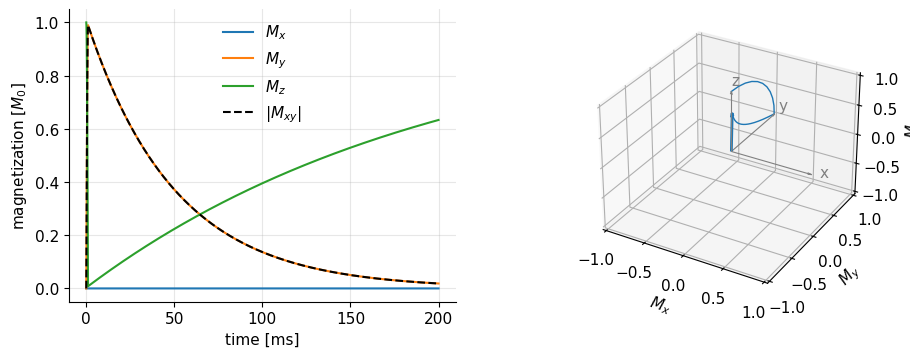

In [12]:
# Interactive explorer: the call to interact() is commented out so that the notebook also runs headless.
# Uncomment the last lines (marked) to get sliders in Jupyter.
try:
    from ipywidgets import interact, FloatSlider

    def explore(flip_deg=90.0, df_Hz=0.0, T2_ms=50.0):
        dt = 1e-4
        b1 = np.zeros(2000, complex)
        b1[:10] = mt.b1_for_flip(np.deg2rad(flip_deg), 10*dt)      # 1 ms hard pulse
        t, M = mt.bloch_simulate(B1=b1, dt=dt, df=df_Hz, T1=4*T2_ms*1e-3, T2=T2_ms*1e-3)
        fig = plt.figure(figsize=(11, 3.8))
        mt.plot_magnetization(t, M, ax=fig.add_subplot(1, 2, 1), components="xyza")
        mt.plot_magnetization_3d(M[:, 0], ax=fig.add_subplot(1, 2, 2, projection="3d"))
        plt.show()

    explore()   # static default
    # --- uncomment for sliders ---
    # interact(explore, flip_deg=FloatSlider(value=90, min=0, max=180, step=5),
    #          df_Hz=FloatSlider(value=0, min=-50, max=50, step=1),
    #          T2_ms=FloatSlider(value=50, min=5, max=200, step=5))
except ImportError:
    print("ipywidgets not available - edit the parameters of explore() by hand.")

## Key takeaways

* The Bloch equation $d\vec M/dt=\gamma\vec M\times\vec B-\text{relaxation}$ has two parts: a **rotation** about $\vec B$ (left-handed, rate $\gamma|\vec B|$, keeps $|\vec M|$) and **relaxation** ($M_{xy}\to0$ with $T_2$, $M_z\to M_0$ with $T_1$; the $M_0/T_1$ term makes $M_0$ the equilibrium).
* Free precession: with $M_{xy}=M_x+iM_y$, $dM_{xy}/dt=-i\omega_0M_{xy}$ ⇒ $M_{xy}(t)=M_{xy}(0)e^{-i\omega_0t}e^{-t/T_2}$.
* Relaxation solutions: $M_{xy}(t)=M_{xy}(0)e^{-t/T_2}$, $M_z(t)=M_z(0)e^{-t/T_1}+M_0(1-e^{-t/T_1})$.
* **Rotating frame** at $\omega_{rf}$: $M'_{xy}=M_{xy}e^{+i\omega_{rf}t}$, effective field $\vec B_{eff}=\vec B-(\omega_{rf}/\gamma)\hat z$; on resonance $B_0$ disappears, the RF becomes a static vector $b_1$, off-resonance leaves $\Delta\omega/\gamma$ along $z$.
* Flip angle $\theta=\gamma\int|b_1|dt$ (5.87 µT for 1 ms gives 90°); the RF phase sets the tip direction.
* Off resonance, $\vec B_{eff}$ tilts towards $z$ and excitation fails beyond ~$\pm\bar\gamma B_1$: pulses have a finite frequency bandwidth (~$1/T_{rf}$).
* Numerically: rotate (exact) then relax (exact) per time step; error ∝ $\Delta t$; simulate in the rotating frame.

## Check your understanding

1. Show from the Bloch equation that $|\vec M|$ stays constant when $T_1,T_2\to\infty$. What happens to $|\vec M|$ when relaxation is included?

<details><summary>Answer</summary>

$\frac{d}{dt}|\vec M|^2=2\vec M\cdot\gamma(\vec M\times\vec B)=0$ because $\vec M\times\vec B\perp\vec M$. With relaxation, $|\vec M|$ generally changes: e.g. after a 90° pulse it first *shrinks* (fast $T_2$ decay) and then grows back to $M_0$ ($T_1$ recovery).

</details>

2. At 3 T, what is the effective field $B_{eff,z}$ in the rotating frame for fat (precessing 447 Hz slower than water) if the RF is tuned to water?

<details><summary>Answer</summary>

$\Delta f=-447$ Hz ⇒ $B_{eff,z}=\Delta f/\bar\gamma=-447/(42.58\times10^6)\approx-10.5$ µT. That is *larger* than the $B_1=5.87$ µT of a 1 ms, 90° hard pulse, so for fat $\vec B_{eff}$ is tilted to only $\alpha=\arctan(250/447)\approx29°$ from the $z$-axis. A simulation (or the excitation-profile plot at 447 Hz) gives $|M_{xy}|\approx0.85$, $M_z\approx0.52$ and a phase that differs from water by ~180°: a 1 ms hard pulse does not excite fat and water equally. Shorter, stronger pulses (larger $\bar\gamma B_1$) reduce the difference.

</details>

3. What $B_1$ is needed for a 180° hard pulse of 0.5 ms? How does the energy deposited compare with a 90° pulse of 1 ms?

<details><summary>Answer</summary>

$B_1=\pi/(\gamma\cdot0.5\,\text{ms})=23.5$ µT. Energy ∝ $B_1^2T_{rf}$: $(23.5)^2\cdot0.5$ vs $(5.87)^2\cdot1$ ⇒ 8× more.

</details>

4. In the lab frame, $\vec M$ precesses at 127.7 MHz after a 90° pulse at 3 T. Describe the same motion in a frame rotating at 127.7 MHz + 100 Hz.

<details><summary>Answer</summary>

$\Delta f=f_0-f_{rf}=-100$ Hz, so in that frame $\vec M$ precesses slowly at 100 Hz in the *opposite* (counter-clockwise) sense, while decaying with $T_2$.

</details>

5. Why does the numerical simulator apply rotation and relaxation as two separate steps, and what limits its accuracy?

<details><summary>Answer</summary>

Each part alone has an exact closed-form solution for constant fields (a rotation; exponential decay/recovery). Splitting introduces an error because the two processes actually act simultaneously; together with holding $\vec B$ constant during a step, this gives an error ∝ $\Delta t$. Choose $\Delta t$ small compared with $T_2$ and with the time over which $\vec B$ changes (and, in the lab frame, compared with the Larmor period).

</details>

---
*Adapted and extended from P. Larson, "Principles of MRI" (MIT License), chapter "Bloch Equation". Changes: term-by-term explanation of the equation, explicit ODE solutions (free precession via $M_{xy}$, relaxation), a proper rotating-frame derivation with $\vec B_{eff}$ and off-resonance, flip angle/RF phase, off-resonant excitation, linear vs circular drive, an explained numerical method with accuracy test; code ported to `mri_tools`. Corrected: handedness of the original code and RF field ($-\sin$), the relaxation-matrix entry (1 → $e^{-t/T_1}$), "relaxation rates" → time constants, typos.*